In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_graphviz
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from graphviz import Source

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

Path("images").mkdir(exist_ok=True)

In [2]:
heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features
y = heart_disease.data.targets

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (303, 13)
Target Shape: (303, 1)


In [3]:
df = X.copy()

df["target"] = y.iloc[:, 0]

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst Five Rows:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["target"].value_counts())

Dataset Shape: (303, 14)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

First Five Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



Statistical Summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000



Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Target Distribution:
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [5]:
y = y.iloc[:, 0]

y = (y > 0).astype(int)

print("Target Distribution:")
print(y.value_counts())

print("\nTarget Labels:")
print("0 = No Heart Disease")
print("1 = Heart Disease")

Target Distribution:
num
0    164
1    139
Name: count, dtype: int64

Target Labels:
0 = No Heart Disease
1 = Heart Disease


In [6]:
X = X.copy()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Features Shape: (303, 13)
Target Shape: (303,)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [7]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical Features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [8]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 242
Testing Samples: 61


In [10]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="entropy",
        random_state=RANDOM_STATE
    ))
])

dt_model.fit(X_train, y_train)

dt_train_pred = dt_model.predict(X_train)
dt_test_pred = dt_model.predict(X_test)

dt_train_accuracy = accuracy_score(y_train, dt_train_pred)
dt_test_accuracy = accuracy_score(y_test, dt_test_pred)

print("Training Accuracy:", dt_train_accuracy)
print("Testing Accuracy:", dt_test_accuracy)

Training Accuracy: 1.0
Testing Accuracy: 0.7868852459016393


In [11]:
print("Training Accuracy:", dt_train_accuracy)
print("Testing Accuracy:", dt_test_accuracy)

print(
    "Accuracy Difference:",
    dt_train_accuracy - dt_test_accuracy
)

Training Accuracy: 1.0
Testing Accuracy: 0.7868852459016393
Accuracy Difference: 0.21311475409836067


In [12]:
depth_values = [2, 3, 4, 5, 7, 10]

train_scores = []
test_scores = []

for depth in depth_values:

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth,
            criterion="entropy",
            random_state=RANDOM_STATE
        ))
    ])

    model.fit(X_train, y_train)

    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

depth_results = pd.DataFrame({
    "Max Depth": depth_values,
    "Training Accuracy": train_scores,
    "Testing Accuracy": test_scores
})

display(depth_results)

,Max Depth,Training Accuracy,Testing Accuracy
0,2,0.772727,0.770492
1,3,0.834711,0.803279
2,4,0.867769,0.786885
3,5,0.904959,0.754098
4,7,0.962810,0.836066
5,10,1.000000,0.786885


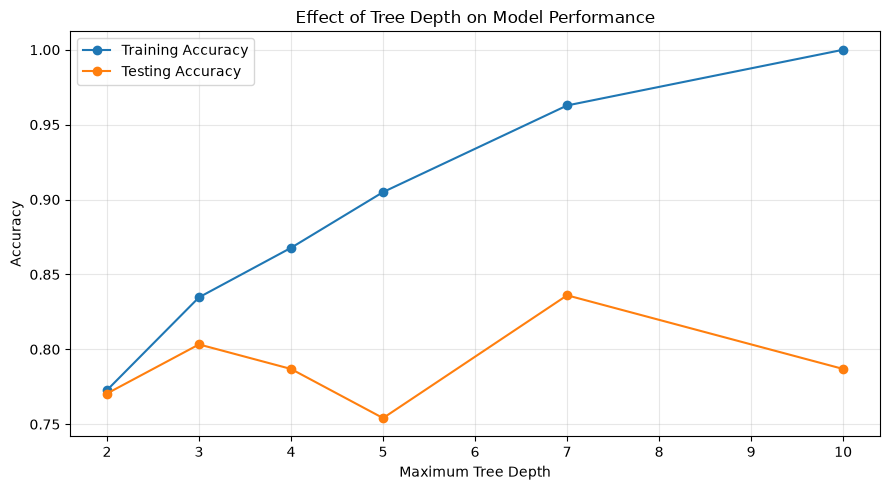

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    depth_values,
    train_scores,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_values,
    test_scores,
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth on Model Performance")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("images/overfitting_analysis.png", dpi=300)
plt.show()

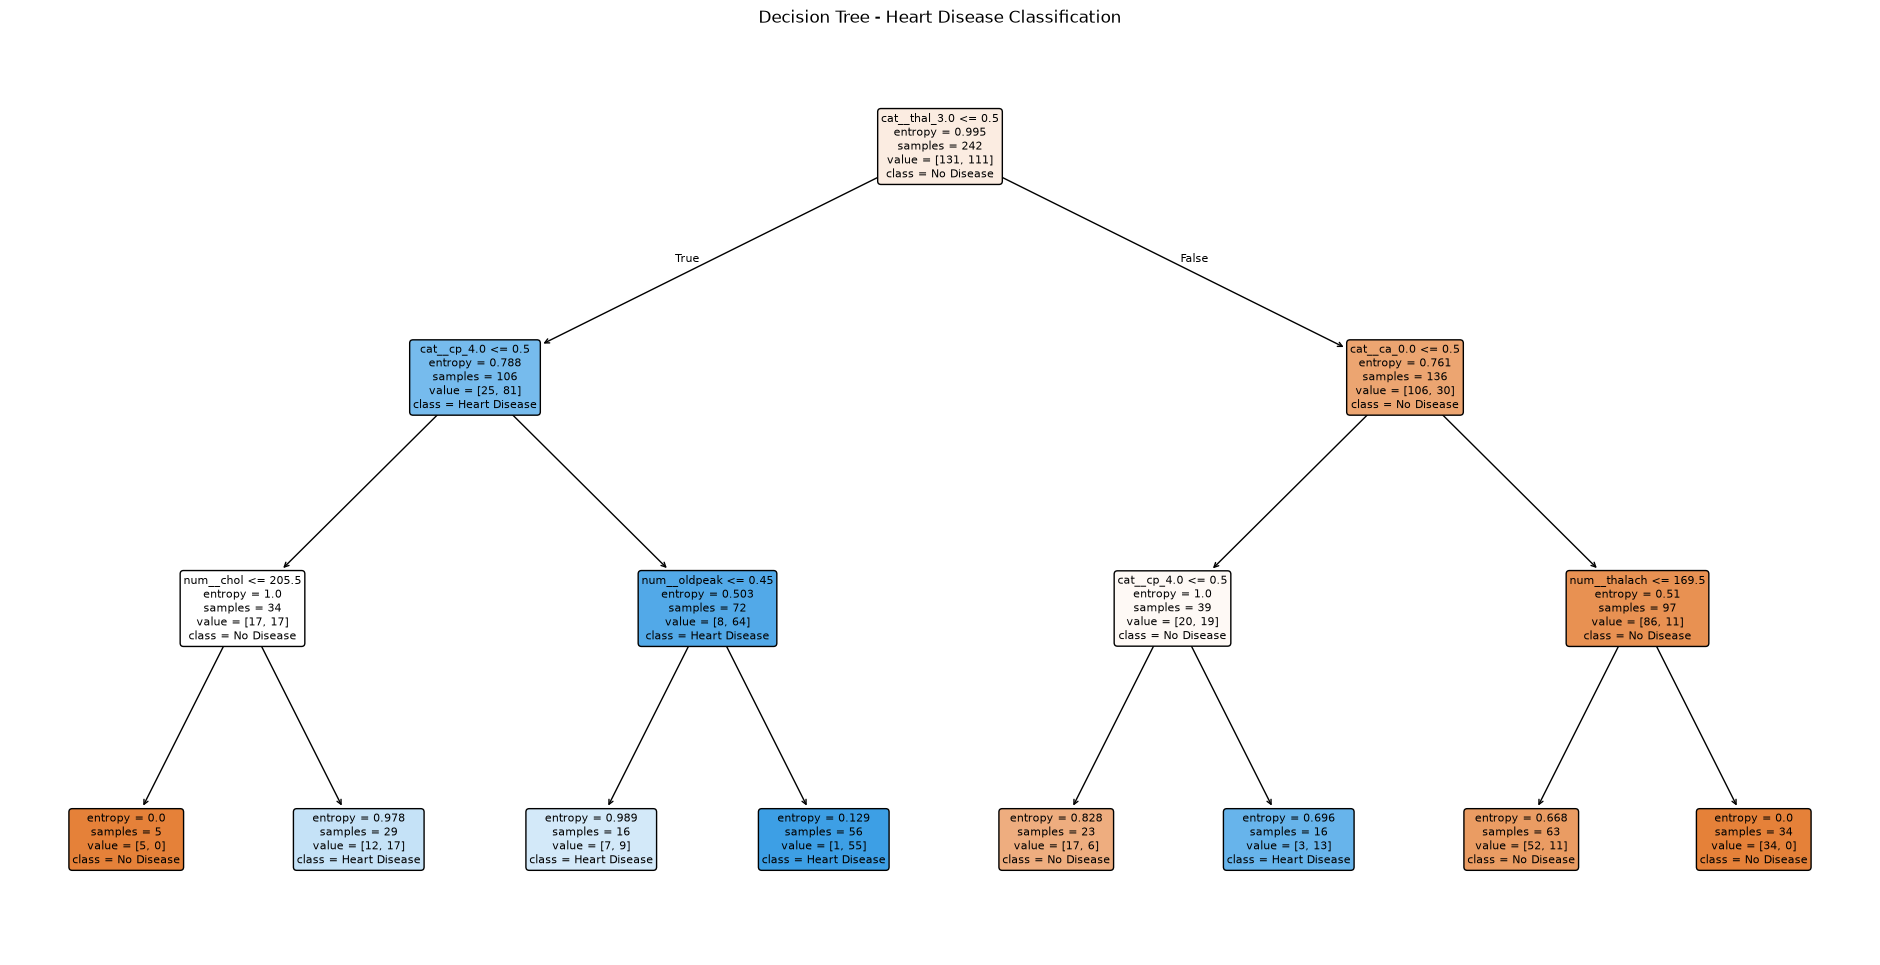

In [14]:
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=3,
        criterion="entropy",
        random_state=RANDOM_STATE
    ))
])

tree_model.fit(X_train, y_train)

fitted_preprocessor = tree_model.named_steps["preprocessor"]

fitted_tree = tree_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    fitted_tree,
    feature_names=feature_names,
    class_names=["No Disease", "Heart Disease"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree - Heart Disease Classification")

plt.savefig(
    "images/decision_tree.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
dot_data = export_graphviz(
    fitted_tree,
    out_file=None,
    feature_names=feature_names,
    class_names=["No Disease", "Heart Disease"],
    filled=True,
    rounded=True,
    special_characters=True
)

graph = Source(dot_data)

graph.render(
    "images/decision_tree_graphviz",
    format="png",
    cleanup=True
)

'images\\decision_tree_graphviz.png'

In [16]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

rf_train_accuracy = accuracy_score(y_train, rf_train_pred)
rf_test_accuracy = accuracy_score(y_test, rf_test_pred)

print("Random Forest Training Accuracy:", rf_train_accuracy)
print("Random Forest Testing Accuracy:", rf_test_accuracy)

Random Forest Training Accuracy: 1.0
Random Forest Testing Accuracy: 0.8688524590163934


In [17]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Training Accuracy": [
        dt_train_accuracy,
        rf_train_accuracy
    ],
    "Testing Accuracy": [
        dt_test_accuracy,
        rf_test_accuracy
    ]
})

display(comparison)

,Model,Training Accuracy,Testing Accuracy
0,Decision Tree,1.0,0.786885
1,Random Forest,1.0,0.868852


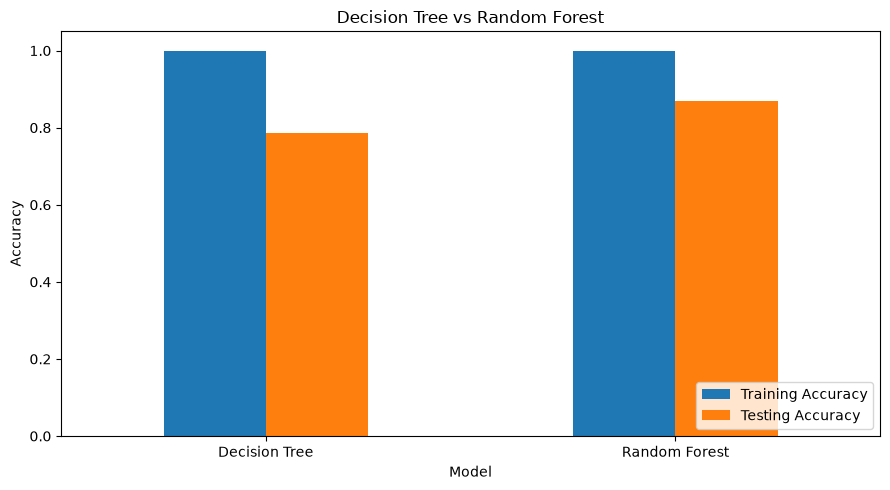

In [18]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig("images/model_comparison.png", dpi=300)

plt.show()

In [19]:
rf_preprocessor = rf_model.named_steps["preprocessor"]

rf_classifier = rf_model.named_steps["classifier"]

rf_feature_names = rf_preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_classifier.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance.head(10))

,Feature,Importance
25,cat__thal_3.0,0.091596
3,num__thalach,0.088328
27,cat__thal_7.0,0.078367
4,num__oldpeak,0.077840
2,num__chol,0.076475
21,cat__ca_0.0,0.075967
0,num__age,0.071819
10,cat__cp_4.0,0.064269
1,num__trestbps,0.060395
16,cat__exang_0.0,0.041315


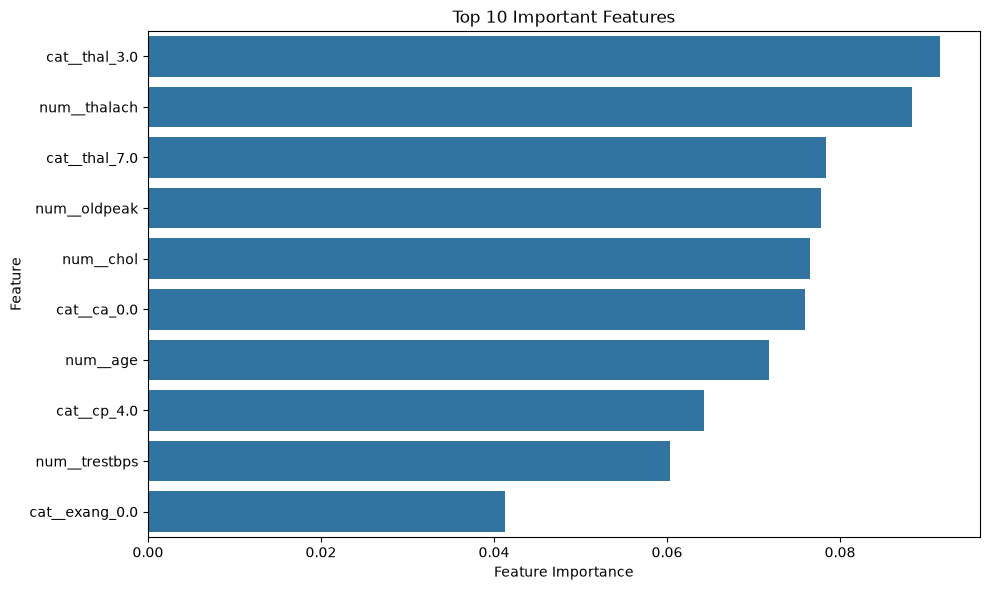

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig("images/feature_importance.png", dpi=300)

plt.show()

In [21]:
print("Decision Tree Report")

print(
    classification_report(
        y_test,
        dt_test_pred,
        target_names=["No Disease", "Heart Disease"]
    )
)

print("Random Forest Report")

print(
    classification_report(
        y_test,
        rf_test_pred,
        target_names=["No Disease", "Heart Disease"]
    )
)

Decision Tree Report
               precision    recall  f1-score   support

   No Disease       0.86      0.73      0.79        33
Heart Disease       0.73      0.86      0.79        28

     accuracy                           0.79        61
    macro avg       0.79      0.79      0.79        61
 weighted avg       0.80      0.79      0.79        61

Random Forest Report
               precision    recall  f1-score   support

   No Disease       0.93      0.82      0.87        33
Heart Disease       0.81      0.93      0.87        28

     accuracy                           0.87        61
    macro avg       0.87      0.87      0.87        61
 weighted avg       0.88      0.87      0.87        61



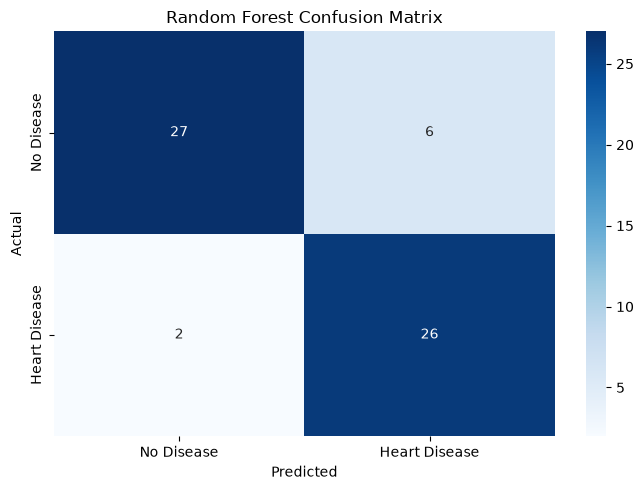

In [22]:
cm = confusion_matrix(y_test, rf_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Heart Disease"],
    yticklabels=["No Disease", "Heart Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Random Forest Confusion Matrix")

plt.tight_layout()

plt.savefig("images/confusion_matrix.png", dpi=300)

plt.show()

In [23]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross-Validation Scores:", cv_scores)

print("Mean CV Accuracy:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())

Cross-Validation Scores: [0.85714286 0.79591837 0.83333333 0.83333333 0.77083333]
Mean CV Accuracy: 0.8181122448979592
Standard Deviation: 0.030707052733897906


In [24]:
final_results = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Testing Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "5-Fold CV Mean Accuracy"
    ],

    "Decision Tree": [
        dt_train_accuracy,
        dt_test_accuracy,
        precision_score(y_test, dt_test_pred),
        recall_score(y_test, dt_test_pred),
        f1_score(y_test, dt_test_pred),
        cross_val_score(
            dt_model,
            X_train,
            y_train,
            cv=cv,
            scoring="accuracy"
        ).mean()
    ],

    "Random Forest": [
        rf_train_accuracy,
        rf_test_accuracy,
        precision_score(y_test, rf_test_pred),
        recall_score(y_test, rf_test_pred),
        f1_score(y_test, rf_test_pred),
        cv_scores.mean()
    ]
})

display(final_results.round(4))

,Metric,Decision Tree,Random Forest
0,Training Accuracy,1.0000,1.0000
1,Testing Accuracy,0.7869,0.8689
2,Precision,0.7273,0.8125
3,Recall,0.8571,0.9286
4,F1-Score,0.7869,0.8667
5,5-Fold CV Mean Accuracy,0.7272,0.8181
